# F27 — Scoring de crédit explicable
**Étudiant :** JANAH Mouad · **Code Apogée :** 25007621 · **Groupe :** G2 · **Module :** BD & DS (S7 FIN/CI)

**Algorithme principal :** Random Forest (n°14) · **Comparaison obligatoire :** Régression logistique (n°8)

## A. Problème
- **Intérêt financier :** une banque doit accepter ou refuser un crédit. Refuser un bon client fait perdre une marge ; accorder un crédit à un mauvais client fait perdre le capital. Le régulateur et le client exigent en plus une décision **explicable**.
- **Question :** un modèle de forêt aléatoire, expliqué par l'importance par permutation et les dépendances partielles, réduit-il le coût de décision par rapport à une référence naïve et à une régression logistique, tout en restant interprétable ?
- **Cible :** `defaut` = 1 si le client est « mauvais » (défaut), 0 sinon.
- **Tâche :** classification binaire à coûts asymétriques. Matrice de coûts classique du jeu German Credit : accorder un crédit à un mauvais client (faux négatif) coûte **5**, refuser un bon client (faux positif) coûte **1**.
- **Métrique de réussite (fixée avant les résultats) :** coût moyen par client sur le test (principal) ; AUC-ROC et rappel de la classe « défaut » (secondaires). Succès = coût inférieur à celui de la référence naïve **et** de la régression logistique.

In [12]:
import os, warnings, datetime
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, recall_score, precision_score
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn import tree
warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
os.makedirs("../figures", exist_ok=True); os.makedirs("../data/raw", exist_ok=True)
COUT_FN, COUT_FP = 5, 1

## B. Données
- **Nom :** Statlog (German Credit Data) · **Organisme :** UCI Machine Learning Repository (Prof. Hans Hofmann) · **URL :** https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data (copie OpenML `credit-g`)
- **Licence :** CC BY 4.0 (à vérifier sur la page UCI) · **Date d'extraction :** affichée par la cellule ci-dessous
- **Unité d'observation :** un demandeur de crédit · **Période / fréquence :** coupe transversale, pas de dimension temporelle (donc découpage stratifié et non chronologique).

In [13]:
LOCAL = "../data/raw/credit_g.csv"
if os.path.exists(LOCAL):
    df = pd.read_csv(LOCAL)
else:
    from sklearn.datasets import fetch_openml
    df = fetch_openml("credit-g", version=1, as_frame=True).frame
    df.to_csv(LOCAL, index=False)
with open("../data/raw/SOURCE.md", "w") as f:
    f.write("Source : UCI Statlog German Credit (OpenML credit-g)\nURL : https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data\n"
            "Licence : CC BY 4.0\nDate d'extraction : " + str(datetime.date.today()) + "\n")
df["defaut"] = (df["class"] == "bad").astype(int)
df = df.drop(columns="class")
df["mensualite"] = df["credit_amount"] / df["duration"]   # variable construite, calcul ligne à ligne : pas de fuite
print(df.shape); df.head()

(1000, 22)


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,...,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,defaut,mensualite
0,<0,6,critical/other existing credit,radio/tv,1169,no known savings,>=7,4,male single,none,...,67,none,own,2,skilled,1,yes,yes,0,194.833333
1,0<=X<200,48,existing paid,radio/tv,5951,<100,1<=X<4,2,female div/dep/mar,none,...,22,none,own,1,skilled,1,none,yes,1,123.979167
2,no checking,12,critical/other existing credit,education,2096,<100,4<=X<7,2,male single,none,...,49,none,own,1,unskilled resident,2,none,yes,0,174.666667
3,<0,42,existing paid,furniture/equipment,7882,<100,4<=X<7,2,male single,guarantor,...,45,none,for free,1,skilled,2,none,yes,0,187.666667
4,<0,24,delayed previously,new car,4870,<100,1<=X<4,3,male single,none,...,53,none,for free,2,skilled,2,none,yes,1,202.916667


In [14]:
print("Doublons :", df.duplicated().sum())
print("Manquants :", int(df.isna().sum().sum()))
print(df["defaut"].value_counts(normalize=True).round(3))
df.describe().T.round(1)

Doublons : 0
Manquants : 0
defaut
0    0.7
1    0.3
Name: proportion, dtype: float64


,count,mean,std,min,25%,50%,75%,max
duration,1000.0,20.9,12.1,4.0,12.0,18.0,24.0,72.0
credit_amount,1000.0,3271.3,2822.7,250.0,1365.5,2319.5,3972.2,18424.0
installment_commitment,1000.0,3.0,1.1,1.0,2.0,3.0,4.0,4.0
residence_since,1000.0,2.8,1.1,1.0,2.0,3.0,4.0,4.0
age,1000.0,35.5,11.4,19.0,27.0,33.0,42.0,75.0
existing_credits,1000.0,1.4,0.6,1.0,1.0,1.0,2.0,4.0
num_dependents,1000.0,1.2,0.4,1.0,1.0,1.0,1.0,2.0
defaut,1000.0,0.3,0.5,0.0,0.0,0.0,1.0,1.0
mensualite,1000.0,167.7,153.5,24.1,89.6,130.3,206.2,2482.7


**Dictionnaire (variables principales)**

| Variable | Rôle | Type | Unité | Manquants |
|---|---|---|---|---|
| `defaut` | cible (1 = mauvais client) | binaire | – | 0 |
| `duration` | explicative | numérique | mois | 0 |
| `credit_amount` | explicative | numérique | DM | 0 |
| `mensualite` | construite = montant / durée | numérique | DM/mois | 0 |
| `age` | explicative | numérique | années | 0 |
| `checking_status` | explicative | catégorielle | solde du compte courant | 0 |
| `credit_history` | explicative | catégorielle | historique de crédit | 0 |
| `savings_status` | explicative | catégorielle | épargne | 0 |

Autres variables (20 au total) : `purpose`, `employment`, `housing`, etc.

## C. Exploration et préparation

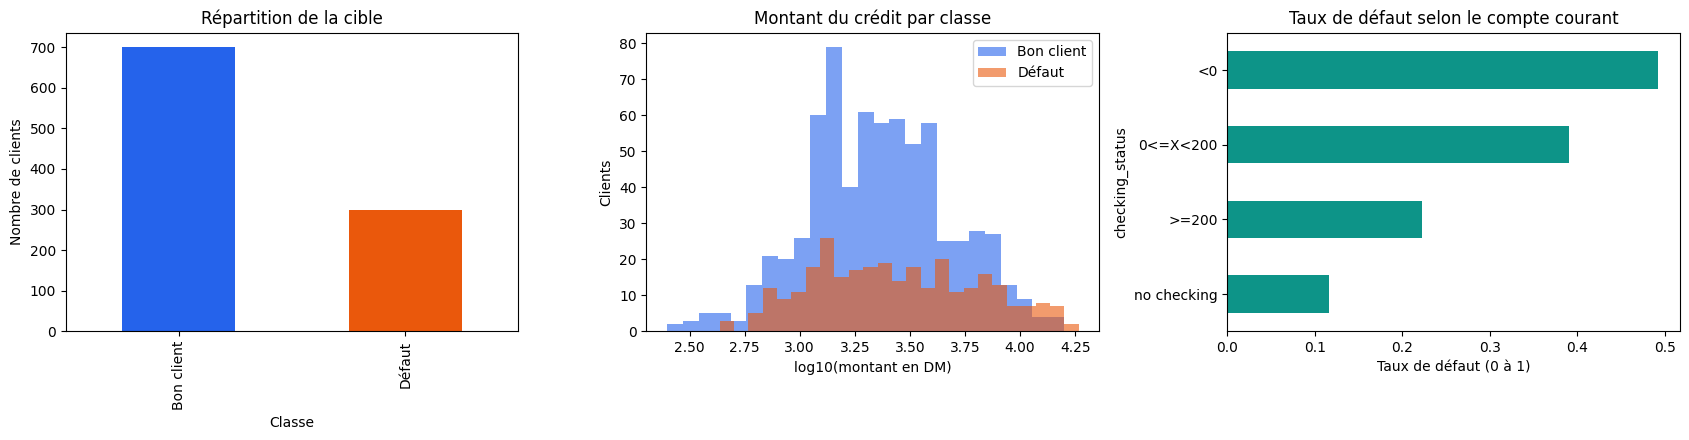

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
# Figure 1 : déséquilibre
df["defaut"].map({0: "Bon client", 1: "Défaut"}).value_counts().plot.bar(ax=ax[0], color=["#2563eb", "#ea580c"])
ax[0].set_title("Répartition de la cible"); ax[0].set_ylabel("Nombre de clients"); ax[0].set_xlabel("Classe")
# Figure 2 : montant par classe
for k, c, l in [(0, "#2563eb", "Bon client"), (1, "#ea580c", "Défaut")]:
    ax[1].hist(np.log10(df.loc[df.defaut == k, "credit_amount"]), bins=25, alpha=.6, color=c, label=l)
ax[1].set_title("Montant du crédit par classe"); ax[1].set_xlabel("log10(montant en DM)"); ax[1].set_ylabel("Clients"); ax[1].legend()
# Figure 3 : taux de défaut par solde du compte
df.groupby("checking_status")["defaut"].mean().sort_values().plot.barh(ax=ax[2], color="#0d9488")
ax[2].set_title("Taux de défaut selon le compte courant"); ax[2].set_xlabel("Taux de défaut (0 à 1)")
plt.tight_layout(); plt.savefig("../figures/fig1_exploration.png", dpi=150); plt.show()

**Interprétation (à compléter après exécution, 2–4 lignes par graphique).**
1. La cible est déséquilibrée (environ 70 % de bons clients, 30 % de défauts) : un découpage stratifié et une métrique à coûts s'imposent, l'exactitude seule serait trompeuse.
2. Les crédits de montant élevé sont davantage associés au défaut : le montant et la durée portent de l'information.
3. Le taux de défaut varie fortement avec le solde du compte courant : c'est une variable très informative, à retrouver dans l'explicabilité.

**Nettoyage :** aucune valeur manquante ni doublon ; les montants sont asymétriques, mais les forêts aléatoires sont insensibles aux transformations monotones, et la régression logistique reçoit des variables standardisées. Aucune valeur extrême supprimée (clients réels, information utile).

In [16]:
X = df.drop(columns="defaut"); y = df["defaut"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
num = X.select_dtypes("number").columns.tolist()
cat = X.select_dtypes(exclude="number").columns.tolist()
# Tout le prétraitement est ajusté dans le Pipeline, donc sur l'entraînement seulement (dans chaque pli de CV)
prep_lr = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat)])
prep_rf = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat)])
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
print(X_tr.shape, X_te.shape, y_tr.mean().round(3), y_te.mean().round(3))

(800, 21) (200, 21) 0.3 0.3


## D. Algorithme retenu : Random Forest (n°14)

**Principe et contexte.** Une forêt aléatoire agrège de nombreux arbres de décision entraînés sur des échantillons bootstrap et des sous-ensembles aléatoires de variables. Elle capte les non-linéarités et les interactions (ex. montant × durée) sans transformation, résiste au surapprentissage mieux qu'un arbre seul et fournit des mesures d'importance. Elle convient au scoring de crédit, où les données sont tabulaires, de taille modeste et mêlent variables numériques et catégorielles. **Alternative comparée :** la régression logistique (n°8), référence réglementaire : très lisible (un coefficient par variable) mais linéaire en log-odds.

**Équation principale.**

$$\hat p(\mathbf x)=\frac1B\sum_{b=1}^{B}T_b(\mathbf x),\qquad \hat y=\mathbb 1\left[\hat p(\mathbf x)\ge \tau\right]$$

- $\mathbf x$ : caractéristiques du client ; $T_b(\mathbf x)\in\{0,1\}$ : vote de l'arbre $b$ ; $B$ : nombre d'arbres ; $\hat p$ : probabilité estimée de défaut ; $\tau$ : seuil de décision.
- Paramètres appris : pour chaque arbre, les variables et seuils de coupure et les feuilles. Chaque coupure minimise l'impureté de Gini $G=1-\sum_k p_k^2$.
- Seuil de Bayes pour la matrice de coûts : refuser si $\hat p\ge \frac{c_{FP}}{c_{FP}+c_{FN}}=\frac16$.
- **Hyperparamètres commentés :** `max_depth` (profondeur maximale : contrôle la complexité, trop grand → surapprentissage) ; `min_samples_leaf` (taille minimale d'une feuille : lisse les prédictions, réduit la variance).

**Schéma de décision :** voir la figure d'un arbre de la forêt (cellule ci-dessous), et le protocole : données → découpage stratifié 80/20 → pipeline (imputation, encodage) → CV 5 plis sur le train (réglage) → seuil de coût choisi sur prédictions hors-pli → modèle figé → test utilisé une seule fois.

## E. Expérimentation

In [17]:
def cout(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return (COUT_FN * fn + COUT_FP * fp) / len(y_true)

# Références naïves
ref_accorde_tout = np.zeros(len(y_te), dtype=int)                 # classe majoritaire : tout accorder
ref_refuse_tout = np.ones(len(y_te), dtype=int)                   # politique fixe : tout refuser
print("Coût 'tout accorder' :", round(cout(y_te, ref_accorde_tout), 3))
print("Coût 'tout refuser'  :", round(cout(y_te, ref_refuse_tout), 3))

Coût 'tout accorder' : 1.5
Coût 'tout refuser'  : 0.7


In [18]:
lr = Pipeline([("prep", prep_lr), ("m", LogisticRegression(max_iter=2000, random_state=SEED))])
gs_lr = GridSearchCV(lr, {"m__C": [0.01, 0.1, 1, 10]}, scoring="roc_auc", cv=cv).fit(X_tr, y_tr)

rf = Pipeline([("prep", prep_rf), ("m", RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1))])
gs_rf = GridSearchCV(rf, {"m__max_depth": [3, 5, 8, None], "m__min_samples_leaf": [1, 5, 10]},
                     scoring="roc_auc", cv=cv).fit(X_tr, y_tr)
print("LR :", gs_lr.best_params_, round(gs_lr.best_score_, 3))
print("RF :", gs_rf.best_params_, round(gs_rf.best_score_, 3))

def seuil_cout(est):
    # seuil choisi sur prédictions hors-pli du TRAIN uniquement
    p = cross_val_predict(est, X_tr, y_tr, cv=cv, method="predict_proba")[:, 1]
    grille = np.linspace(0.05, 0.9, 86)
    c = [cout(y_tr, (p >= t).astype(int)) for t in grille]
    return grille[int(np.argmin(c))]
tau_lr, tau_rf = seuil_cout(gs_lr.best_estimator_), seuil_cout(gs_rf.best_estimator_)
print("Seuils :", round(tau_lr, 2), round(tau_rf, 2))

LR : {'m__C': 0.1} 0.782
RF : {'m__max_depth': 8, 'm__min_samples_leaf': 1} 0.797
Seuils : 0.18 0.22


In [19]:
res = []
for nom, est, tau in [("Régression logistique", gs_lr.best_estimator_, tau_lr), ("Random Forest", gs_rf.best_estimator_, tau_rf)]:
    p_te = est.predict_proba(X_te)[:, 1]; yhat = (p_te >= tau).astype(int)
    p_tr = est.predict_proba(X_tr)[:, 1]
    res.append({"Modèle": nom, "Coût moyen (test)": cout(y_te, yhat), "AUC (test)": roc_auc_score(y_te, p_te),
                "Rappel défaut": recall_score(y_te, yhat), "Précision défaut": precision_score(y_te, yhat),
                "AUC (train)": roc_auc_score(y_tr, p_tr)})
res.append({"Modèle": "Référence : tout accorder", "Coût moyen (test)": cout(y_te, ref_accorde_tout), "AUC (test)": 0.5,
            "Rappel défaut": 0.0, "Précision défaut": np.nan, "AUC (train)": np.nan})
res.append({"Modèle": "Référence : tout refuser", "Coût moyen (test)": cout(y_te, ref_refuse_tout), "AUC (test)": 0.5,
            "Rappel défaut": 1.0, "Précision défaut": y_te.mean(), "AUC (train)": np.nan})
tab = pd.DataFrame(res).set_index("Modèle").round(3); tab

,Coût moyen (test),AUC (test),Rappel défaut,Précision défaut,AUC (train)
Modèle,,,,,
Régression logistique,0.535,0.808,0.883,0.424,0.826
Random Forest,0.535,0.809,0.900,0.412,0.992
Référence : tout accorder,1.500,0.500,0.000,NaN,NaN
Référence : tout refuser,0.700,0.500,1.000,0.300,NaN


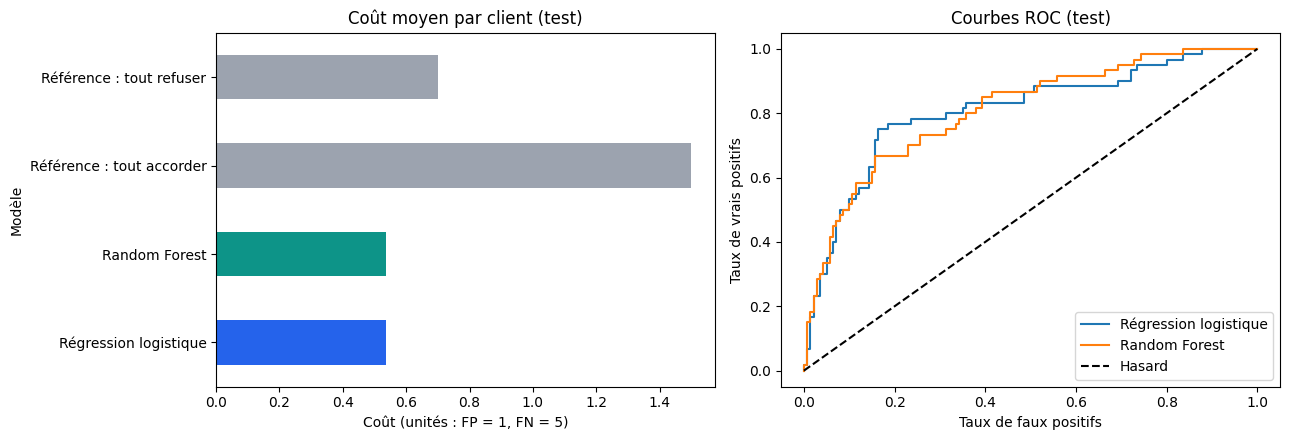

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
tab["Coût moyen (test)"].plot.barh(ax=ax[0], color=["#2563eb", "#0d9488", "#9ca3af", "#9ca3af"])
ax[0].set_title("Coût moyen par client (test)"); ax[0].set_xlabel("Coût (unités : FP = 1, FN = 5)")
for nom, est in [("Régression logistique", gs_lr.best_estimator_), ("Random Forest", gs_rf.best_estimator_)]:
    f, t, _ = roc_curve(y_te, est.predict_proba(X_te)[:, 1]); ax[1].plot(f, t, label=nom)
ax[1].plot([0, 1], [0, 1], "k--", label="Hasard"); ax[1].set_title("Courbes ROC (test)")
ax[1].set_xlabel("Taux de faux positifs"); ax[1].set_ylabel("Taux de vrais positifs"); ax[1].legend()
plt.tight_layout(); plt.savefig("../figures/fig2_resultats.png", dpi=150); plt.show()

In [21]:
# Analyse des erreurs (Random Forest)
est = gs_rf.best_estimator_; yhat = (est.predict_proba(X_te)[:, 1] >= tau_rf).astype(int)
print(pd.DataFrame(confusion_matrix(y_te, yhat), index=["Réel bon", "Réel défaut"], columns=["Prédit bon", "Prédit défaut"]))
fn = X_te[(y_te == 1) & (yhat == 0)]
print("Défauts non détectés (faux négatifs) :", len(fn))
print(fn[["duration", "credit_amount", "age"]].describe().round(0).loc[["mean", "50%"]])
print("Écart AUC train vs CV (surapprentissage) :", round(tab.loc['Random Forest', 'AUC (train)'], 3), "vs", round(gs_rf.best_score_, 3))

             Prédit bon  Prédit défaut
Réel bon             63             77
Réel défaut           6             54
Défauts non détectés (faux négatifs) : 6
      duration  credit_amount   age
mean      14.0         2455.0  33.0
50%       12.0         1888.0  28.0
Écart AUC train vs CV (surapprentissage) : 0.992 vs 0.797


## Explicabilité

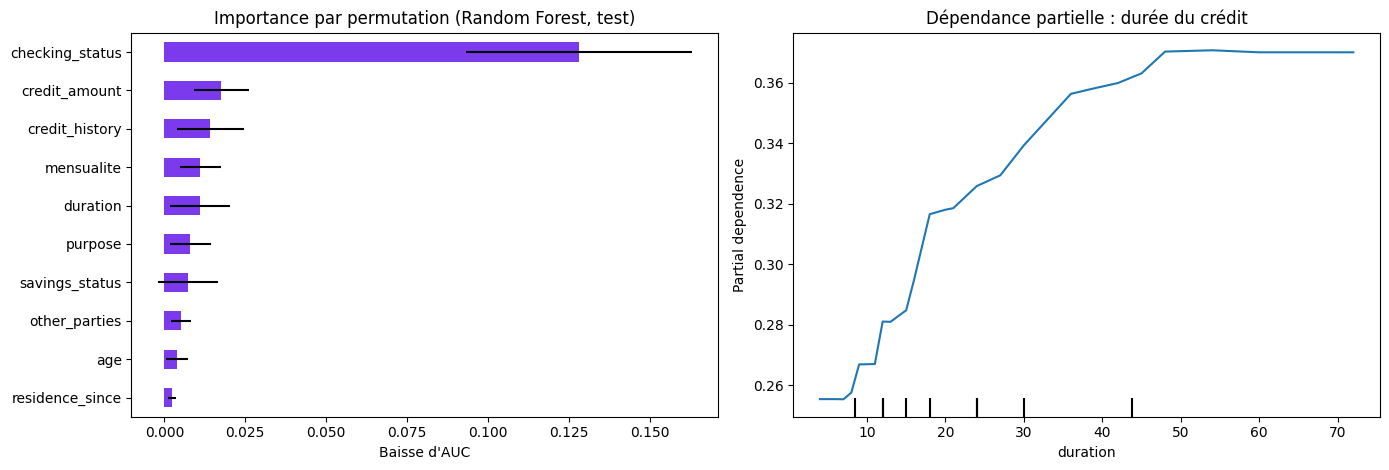

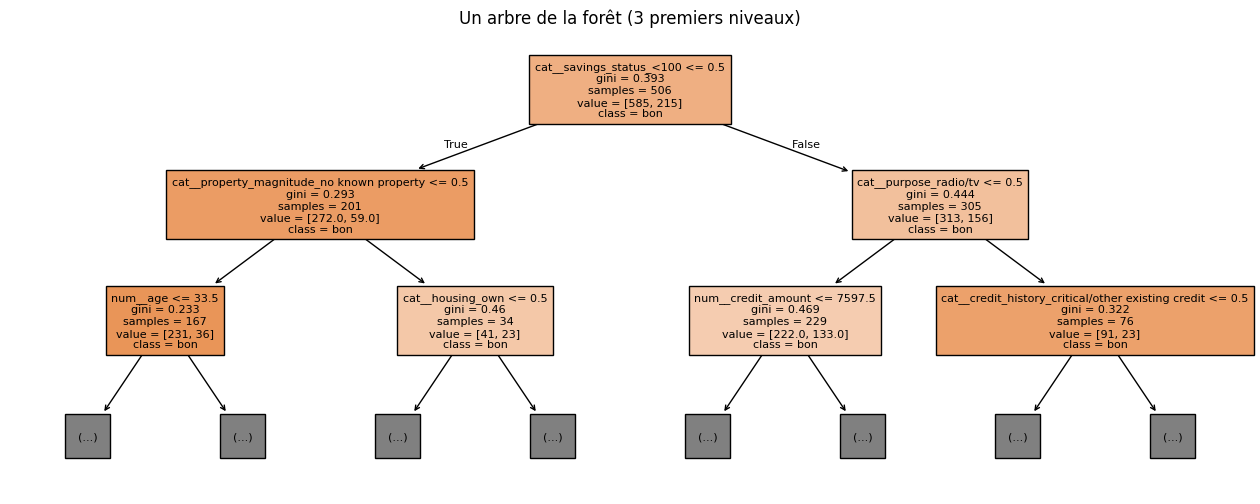

cat__checking_status_no checking                     -0.71
cat__credit_history_critical/other existing credit   -0.52
cat__purpose_used car                                -0.42
cat__employment_4<=X<7                               -0.34
cat__personal_status_male single                     -0.34
cat__property_magnitude_no known property             0.32
cat__purpose_new car                                  0.33
cat__purpose_education                                0.38
cat__savings_status_<100                              0.46
cat__checking_status_<0                               0.53
dtype: float64


In [22]:
est = gs_rf.best_estimator_
pi = permutation_importance(est, X_te, y_te, scoring="roc_auc", n_repeats=20, random_state=SEED)
imp = pd.Series(pi.importances_mean, index=X_te.columns).sort_values().tail(10)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
imp.plot.barh(ax=ax[0], color="#7c3aed", xerr=pd.Series(pi.importances_std, index=X_te.columns)[imp.index])
ax[0].set_title("Importance par permutation (Random Forest, test)"); ax[0].set_xlabel("Baisse d'AUC")
PartialDependenceDisplay.from_estimator(est, X_te, ["duration"], ax=ax[1], kind="average")
ax[1].set_title("Dépendance partielle : durée du crédit"); ax[1].set_xlabel("Durée (mois)"); ax[1].set_ylabel("Probabilité de défaut")
plt.tight_layout(); plt.savefig("../figures/fig3_explicabilite.png", dpi=150); plt.show()

# Schéma d'un arbre de la forêt (profondeur limitée pour la lisibilité)
names = est.named_steps["prep"].get_feature_names_out()
plt.figure(figsize=(16, 6))
tree.plot_tree(est.named_steps["m"].estimators_[0], max_depth=2, feature_names=names, class_names=["bon", "défaut"], filled=True, fontsize=8)
plt.title("Un arbre de la forêt (3 premiers niveaux)"); plt.savefig("../figures/fig4_arbre.png", dpi=150); plt.show()

# Lecture de la régression logistique : coefficients (odds ratios)
lrm = gs_lr.best_estimator_
coef = pd.Series(lrm.named_steps["m"].coef_[0], index=lrm.named_steps["prep"].get_feature_names_out()).sort_values()
print(pd.concat([coef.head(5), coef.tail(5)]).round(2))